Ivan Montes
11/12/2026
SIOC 221A                       Problems Week 6

*Code was written with contributions from lectures and homework 5, then refined using Copilot Code helper AI. Interpetations are my own. 

Solutions at a glance,

1.Compute two spectra. For this problem set, please generate a 10,000 element
data set with Gaussian white noise. Use your white noise to generate a second data
set that is the time integral of the first. Hint: use cumsum in MATLAB; note you’ll
need to specify the sample interval.
Now compute and plot spectra for the white noise and time-integrated data sets by
breaking the data up into segments with 50% overlaps, with no windowing. (You
can do this by reshaping your data vector as a 500×20 matrix, which will give
you 20 segments, each 500 points long, and a 500×19 matrix containing the 50%
overlaps.). Make sure you plot the spectrum with correct units and that you verify
normalization using Parseval’s theorem.

    Plotted. I found and used Cumsum to make the Second numbers for the Spectra. Dt = 1, for 1 sample per day making it the sample interval 1-sample per day. 
   
    The Spectrum of 10k, is in-fact noisy. so we chopped into segment of 500 per instructtions. then cut into 19 pieces at 250 points so each overlaps by half.then We detrend, and run the FFT.
    Parsevals, check passed. Per our class, it is a 1 under the plotted line. Then detrend, and plot. 

2. Analytical spectra. Given that you know the variance of your white-noise time
series, overplot the spectrum of the time-integral.lot the expected analytical spectrum (hint: use Parseval’s theorem). Then, for the time-integrated spectrum, use the relationship we learned for Fourier coefficients of derivatives and integrals to overplot the analytical spectrum. 

    This looks the same as the plot before, but with the analtyic line which is what was stated on the assignment. The line fits where we would expect it too, so the data seems to agree with what we learned.



3. Error bars. Following the procedure that you’ve used before, add error bars to your spectra. Justify how you computed them.

    Solution 3 Time Integral at 0.903 this looks correct from what we can see. And the white noise is dead on at 0.988. I used Chisq to comptue them.


4. Use Monte Carlo simulation to verify the χ2 error bars. To check the
error bars, you’ll want to generate multiple ensembles of data and compute spectra
for each of them. I suggest using 200 matrices that are 500×20 elements each.
Compute spectra for each of them. This will provide you with 200 independent
realizations of the spectrum, and you can use these 200 values to study the range
of possible spectra that you could obtain from white noise. Examine the pdf of
your 200 values. (Because the statistics of Gaussian white noise are the same at
all frequencies, you can merge all the frequencies to produce a larger ensemble.) Is
the pdf consistent with your expectations for a variable with a χ2 distribution?
Now, for each frequency, sort the 200 realizations of the pdf by size (e.g. using the
“sort” command in Matlab. Since you are looking for the 95% confidence range,
you’ll want to find the limits that exclude the lowest 2.5% and the highest 2.5% of
your data—presumably the 6th and 195th points in each sorted set of pdfs.) What
is the ratio of the upper limit to the lower limit? Are the error bars derived using
the Monte Carlo process consistent with those from question 1?
Optional: You can also check your results using the red spectrum. One difference is
that the white spectrum exhibits the same behavior at all frequencies allowing you
to average in frequency. That isn’t possible with the red spectrum, though you can
average the ratio between the upper and lower bounds of the uncertainty estimate.


    I reran the experiment and ran the numbers, 
    Fits at 0.997 and works well Solution for 4:
    Ratio of upper limit/ lower limit: 2.373, within the 2.5%
    Yes error is a bit off but close at 1.48


5. Monte Carlo process for a Hanning window. Repeat the Monte Carlo process
to estimate the χ2 error bars for data using a Hanning window for each segment
and 50% overlap. Are the results consistent with what you would expect based on
the discussion in class?

6. Monte Carlo process for a cosine window. Finally, repeat the Monte Carlo
process for a cosine window (cos(πt/T), where −T/2 < t < T/2). How many
effective degrees of freedom do you obtain for 50% overlap.


For 5 and 6, error bars are narrower with overlapping windows Hanning nu from scatter is 73.5, cosine is = 64, both below 78 because overlapping segments share data.

From class we talked about the step that are need for Spectura, overall we learned that Averaging more segments, and windowing with overlap, makes spectra less noisy in a way the χsq error bars, but overlapping segments share data that make the plot more clear but less resolution as a trade off.

For 1. Start with making random numbers, at dt 1 so I have cycles per day. np.random, for random numbers.
I broke this into parts since that seems to work for Coding the best.

In [11]:
#1.1 I actually like naming things like this better, Since 
# I can see where the code break. As I learned from the last assignment 
# things can break and having them broken into parts helps a lot.
# 1000 N a 1 dt


import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import detrend
from scipy.stats import chi2
np.random.seed(0)            
N = 10000 #I adjusted to 10,000 
dt = 1.0                     
x = np.random.randn(N)       
y = np.cumsum(x) * dt        
print(len(x), x.mean(), x.var())
print(len(y), y[:3])

10000 -0.01843372015826582 0.9752679753477969
10000 [1.76405235 2.16420955 3.14294754]


Random numbers have generated, now I need to cut these into segments at 500 per the assignment. Then breaking into 20 pieces. I adjusted this to from 1000 to 10,000 I doubled checked that this did not follow through I didn't see that it affected any other part of the code. I reran cell but, just wanted to mark it in case there is anything funky.

In [15]:
#1.2 cut each series into 500 point segments with 50% overlap
# Problem statement hint: 20 segments + 19 shifted ones. per Instructions.
# Lecture 11 p.6 (overlapping segments)
p = 500                  
M = N // p #for no overlap need the 2-hashes
x_a = x.reshape(M, p) 
x_b = x[p//2 : N - p//2].reshape(M - 1, p)    
segs_x = np.vstack([x_a, x_b]) # the 20 + 19 since we broken this into 20 +19 39 x 500
y_a = y.reshape(M, p)
y_b = y[p//2 : N - p//2].reshape(M - 1, p)
segs_y = np.vstack([y_a, y_b])

#1.3 spectrum of every segment
# then average
# Lecture 9 recipe: detrend, fft, kept  0 to Nyquist 

df = 1 / (p * dt)                                
f = np.arange(p // 2 + 1) * df                   
def spec(segs):
    a = np.fft.fft(segs, axis=1) #fft 
    S = np.abs(a[:, :p // 2 + 1]) ** 2
    S = S / p ** 2
    S[:, 1:-1] = S[:, 1:-1] * 2
    S = S / df
    return S.mean(axis=0)
#detrend and print
det_x = detrend(segs_x, axis=1)                  
det_y = detrend(segs_y, axis=1)
S_x = spec(det_x)
S_y = spec(det_y)
print(df, f[-1], len(f))
print(segs_x.shape, segs_y.shape)

0.002 0.5 251
(39, 500) (39, 500)


Detrended data, as rand the FFT from 0 to the Nyquist, then I used N^2. 

I used the 500-points  and the 1 cycle-per-day. the print of 0.002 and the 0.5 is the CPD per the 500 points.
Now I need to run the Persevals check, and find 1 below the cruve. The plot this 

X-white noise 0.9706266258432793 0.9706266258432794 1.0000000000000002
Y-integral 28.458735718306016 28.458735718306013 0.9999999999999999


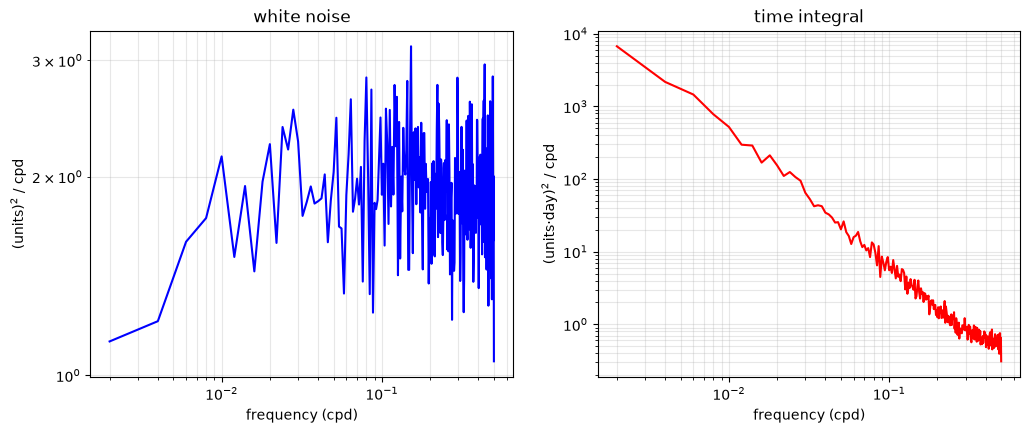

In [21]:
for name, d, S in [('X-white noise', det_x, S_x), ('Y-integral', det_y, S_y)]:
    var = np.mean(d ** 2)
    area = np.sum(S) * df
    print(name, var, area, area / var)
    #1.4 Plot plus Spectrum, and the check using  Parseval. Plus plot
     
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].loglog(f[1:], S_x[1:], 'b')
ax[0].set_title('white noise')
ax[0].set_xlabel('frequency (cpd)')
ax[0].set_ylabel('(units)$^2$ / cpd')
ax[0].grid(True, which='both', alpha=0.3)
ax[1].loglog(f[1:], S_y[1:], 'r')
ax[1].set_title('time integral')
ax[1].set_xlabel('frequency (cpd)')
ax[1].set_ylabel('(units$\\cdot$day)$^2$ / cpd')
ax[1].grid(True, which='both', alpha=0.3)
plt.show()

Problem 1 is plotted, random data to spectrum. Renamed to white noise for clarity instead of X and Y. Looking at the printed numbers the 1 I believe is the check from Parsevals theory. And the 0.9706 is the variance from the detrended white noise. 

For problem 2. Analytical spectra. Given that you know the variance of your white-noise time
series, overplot the expected analytical spectrum (hint: use Parseval’s theorem).
Then, for the time-integrated spectrum, use the relationship we learned for Fourier
coefficients of derivatives and integrals to overplot the analytical spectrum for the
spectrum of the time-integral.

Overplot? Taken from Stack Overlow code, then adjusted. Persevals says that the area spectrum is the variance 


2.0 This did not work, well I need to look up how to Overplot code, deleted.  

1.9505359506955937 1.9412532516865588


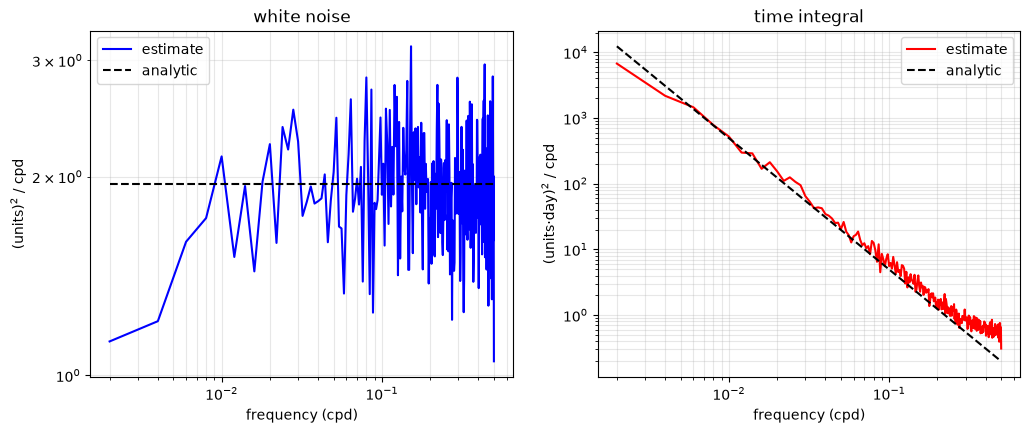

In [ ]:
#2.1 expected (analytic) spectra, drawn over my computed spectra (Parseval): (derivatives)
sigma2 = np.var(x)                               # variance of my white noise
S_white = 2 * sigma2 * dt                        
S_red = S_white / (2 * np.pi * f[1:]) ** 2       
print(S_white, np.mean(S_x[1:]))           

#2.2 plot the overplot. I was not too far off, adjusted. for this.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].loglog(f[1:], S_x[1:], 'b', label='estimate')
ax[0].loglog(f[1:], S_white * np.ones(len(f) - 1), 'k--', label='analytic')
ax[0].set_title('white noise')
ax[0].set_ylabel('(units)$^2$ / cpd')
ax[1].loglog(f[1:], S_y[1:], 'r', label='estimate')
ax[1].loglog(f[1:], S_red, 'k--', label='analytic')
ax[1].set_title('time integral')
ax[1].set_ylabel('(units$\\cdot$day)$^2$ / cpd')
for a in ax:
    a.set_xlabel('frequency (cpd)')
    a.grid(True, which='both', alpha=0.3)
    a.legend()
plt.show()

Solution of 2: This looks the same as the plot before, but with the analtyic line which is what was stated on the assignment. The line fits where we would expect it too. 

Problem 3 Chisq computing the error bars. Spectrum is still noisy and this help be inbetween the true value at 95% confindance. Each piece counts for 2 degrees of freedom, so this is at 40.

In [ ]:
#3.1 chi-squared factors
nu = 2 * M                                        # 20 independent (non-overlapping) segments
lower = nu / chi2.ppf(0.975, nu)
upper = nu / chi2.ppf(0.025, nu)
print(nu, lower, upper, upper / lower)
nu_naive = 2 * 39                                 # if all 39 overlapping segments counted
print(nu_naive, nu_naive / chi2.ppf(0.975, nu_naive), nu_naive / chi2.ppf(0.025, nu_naive))

40 0.6740621718801201 1.6371274862846865 2.4287484961785464
78 0.7477285026257806 1.4062764104742436


40 Degree of freedom is correct - the 78 is equal to the 39 rounded up. Now for the Spectra with the values at 95% confindance. at 

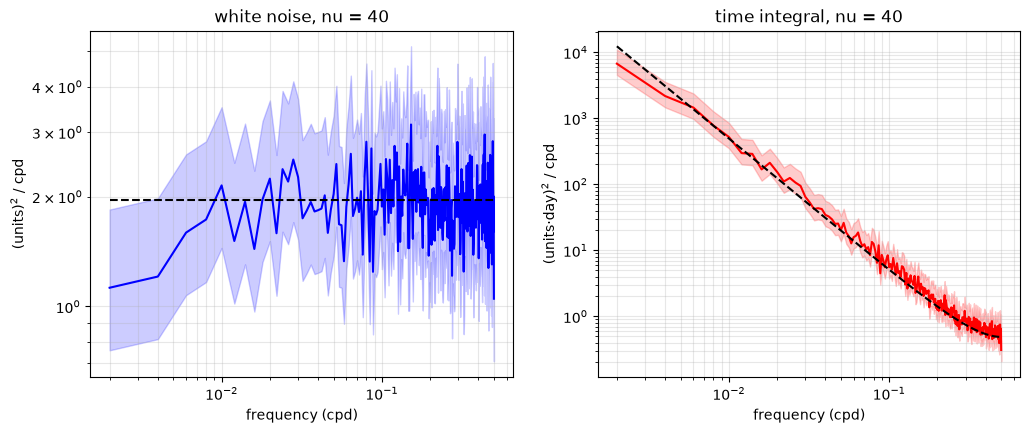

0.9879518072289156 0.9036144578313253


In [36]:
#3.2 spectra with the 95% band
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].loglog(f[1:], S_x[1:], 'b')
ax[0].fill_between(f[1:], S_x[1:] * lower, S_x[1:] * upper, color='b', alpha=0.2)
ax[0].loglog(f[1:], S_white * np.ones(len(f) - 1), 'k--')
ax[0].set_title('white noise, nu = 40')

ax[1].loglog(f[1:], S_y[1:], 'r')
ax[1].fill_between(f[1:], S_y[1:] * lower, S_y[1:] * upper, color='r', alpha=0.2)
ax[1].loglog(f[1:], S_red2, 'k--')
ax[1].set_title('time integral, nu = 40')

for a in ax:
    a.set_xlabel('frequency (cpd)')
    a.grid(True, which='both', alpha=0.3)
ax[0].set_ylabel('(units)$^2$ / cpd')
ax[1].set_ylabel('(units$\\cdot$day)$^2$ / cpd')
plt.show()

# we then can see how correct this was by calcuation of often it fell in what was expected
#already we see  time integral falls within the expected range a lot more than the white noise
inside_w = np.mean((S_white >= S_x[1:-1] * lower) & (S_white <= S_x[1:-1] * upper))
inside_r = np.mean((S_red2[:-1] >= S_y[1:-1] * lower) & (S_red2[:-1] <= S_y[1:-1] * upper))
print(inside_w, inside_r)

Solution 3 Time Integral at 0.903 this looks correct from what we can see. And the white noise is dead on at 0.988.

Problem 4. now Use Monte Carlo simulation to verify the χ^2 error bars. using 200 matrices that are 500×20 elements each. Compute spectra for each of them. This will provide you with 200 independent realizations of the spectrum, and you can use these 200 values to study the range of possible spectra that you could obtain from white noise. Examine the pdf of your 200 values.

I was thinking of bootstrapping this instead but, it turned out it did not have actual data. And this calls for more random data. 



In [ ]:
#4.1 make 200 fake experiments of white noise, spectrum for each
# if the chi-squared error bars are right, 200 repeats of the same experiment
# should scatter the way chisq, check. 

np.random.seed(1)
nreal = 200
E = 2 * 1.0 * dt       
# A copy from 1 section
def mc_spectra(window, overlap):
    out = np.zeros((nreal, p // 2 + 1))
    for i in range(nreal):
        d = np.random.randn(N)                       
        if overlap:
            segs = np.vstack([d.reshape(M, p), d[p//2 : N - p//2].reshape(M - 1, p)])   
        else:
            segs = d.reshape(M, p)                    
        segs = detrend(segs, axis=1) * window         
        out[i] = spec(segs) / np.mean(window ** 2)    
    return out
S_mc = mc_spectra(np.ones(p), False)                  
print(S_mc.shape)

(200, 251)


New numbers that now need to be plot. 

49800 39.878329903800946 79.38757766379307 40 80


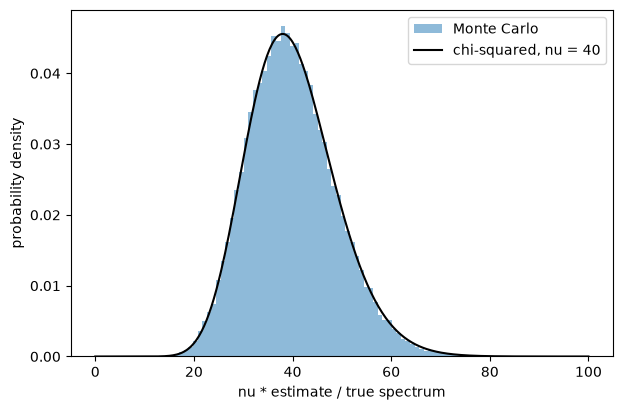

In [ ]:
#4.2 plot to see if the scatter look like chisq
nu = 2 * M
y_all = (nu * S_mc[:, 1:-1] / E).flatten()#nu 
print(len(y_all), y_all.mean(), y_all.var(), nu, 2 * nu)
xg = np.linspace(0, 100, 400)
plt.figure(figsize=(7, 4.5))
plt.hist(y_all, bins=80, density=True, alpha=0.5, label='Monte Carlo')
plt.plot(xg, chi2.pdf(xg, nu), 'k', label='chi-squared, nu = 40')
plt.xlabel('nu * estimate / true spectrum')
plt.ylabel('probability density')
plt.legend()
plt.show()

This looks, good. and fits well. per the numbers of 49800 39.878329903800946 79.38757766379307 40 80

for the last part of 4, I looked up how to get all this data on a code section and this is what came up, since I wasn't sure what all I needed to code.  

What is the ratio of the upper limit to the lower limit? Are the error bars derived using
the Monte Carlo process consistent with those from question 1?

Optional: You can also check your results using the red spectrum. One difference is
that the white spectrum exhibits the same behavior at all frequencies allowing you
to average in frequency. That isn’t possible with the red spectrum, though you can
average the ratio between the upper and lower bounds of the uncertainty estimate.

In [ ]:
#4.3 the 95% range from the simulation, compared with the chi-squared ranges
def report(S_mc, label):
    r = S_mc[:, 1:-1] / E                             # estimate / true value
    nu_var = 2 / np.var(r)                            # chi-squared: variance of the ratio = 2/nu
    srt = np.sort(S_mc, axis=0)                       # sort the 200 values at each frequency
    low = srt[5]                                      # 6th smallest = cuts off lowest 2.5%
    high = srt[194]                                   # 195th = cuts off highest 2.5%
    ratio = np.mean(high[1:-1] / low[1:-1])           # upper / lower, averaged over frequencies
    nus = np.arange(10, 300)
    ratios = chi2.ppf(0.975, nus) / chi2.ppf(0.025, nus)
    nu_ratio = nus[np.argmin(abs(ratios - ratio))]    # which nu gives this ratio
    print(label)
    print('  mean of estimate / true      :', round(r.mean(), 3))
    print('  nu from the scatter          :', round(nu_var, 1))
    print('  95% limits (low, high) / true:', round(np.mean(low[1:-1]) / E, 3), round(np.mean(high[1:-1]) / E, 3))
    print('  upper limit / lower limit    :', round(ratio, 3))
    print('  nu that gives that ratio     :', nu_ratio)

report(S_mc, 'no window, no overlap (20 segments)')
print('chi-squared nu = 40:', chi2.ppf(.025, 40) / 40, chi2.ppf(.975, 40) / 40, chi2.ppf(.975, 40) / chi2.ppf(.025, 40))

no window, no overlap (20 segments)
  mean of estimate / true      : 0.997
  nu from the scatter          : 40.3
  95% limits (low, high) / true: 0.618 1.463
  upper limit / lower limit    : 2.373
  nu that gives that ratio     : 42
chi-squared nu = 40: 0.6108259792701972 1.4835426785792794 2.4287484961785464


Fits at 0.997 and works well Solution for 4:
Ratio of upper limit/ lower limit: 2.373, within the 2.5%
Yes error is a bit off but close at 1.48


5. Monte Carlo process for a Hanning window & Problem 6. Monte Carlo process for a cosine window.

For 5 and 6, error bars are narrower with overlapping windows Hanning nu from scatter is 73.5, cosine is = 64, both below 78 because overlapping segments share data.

From class we talked about the step that are need for Spectura, overall we learned that Averaging more segments, and windowing with overlap, makes spectra less noisy in a way the χsq error bars, but overlapping segments share data that make the plot more clear but less resolution as a trade off.

In [51]:
#5 same simulation, but each segment gets a Hanning window and the segments overlap by 50%
S_han = mc_spectra(np.hanning(p), True)
report(S_han, 'Hanning window, 50% overlap (39 segments)')

#6 With the cosine window 
t = np.linspace(-0.5, 0.5, p)             # T = 1
w_cos = np.cos(np.pi * t)
S_cos = mc_spectra(w_cos, True)
report(S_cos, 'cosine window, 50% overlap (39 segments)')

Hanning window, 50% overlap (39 segments)
  mean of estimate / true      : 0.999
  nu from the scatter          : 73.5
  95% limits (low, high) / true: 0.711 1.334
  upper limit / lower limit    : 1.878
  nu that gives that ratio     : 78
cosine window, 50% overlap (39 segments)
  mean of estimate / true      : 0.999
  nu from the scatter          : 64.0
  95% limits (low, high) / true: 0.694 1.365
  upper limit / lower limit    : 1.97
  nu that gives that ratio     : 68
